In [1]:
import pandas as pd

# Učitavanje CSV datoteke
df = pd.read_csv("student-por.csv", sep=';')

# Prikaz prvih redova
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
# Provjera ima li nedostajućih vrijednosti
df.isnull().sum()


school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [3]:
# Pretvaranje svih kategorijalnih varijabli u numeričke
df_encoded = pd.get_dummies(df, drop_first=True)

# Prikaz dimenzija i prvih redova
df_encoded.shape, df_encoded.head()


((649, 42),
    age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
 0   18     4     4           2          2         0       4         3      4   
 1   17     1     1           1          2         0       5         3      3   
 2   15     1     1           1          2         0       4         3      2   
 3   15     4     2           1          3         0       3         2      2   
 4   16     3     3           1          2         0       4         3      2   
 
    Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
 0     1  ...             True           False           True       False   
 1     1  ...            False           False          False        True   
 2     2  ...             True           False           True       False   
 3     1  ...             True           False          False        True   
 4     1  ...            False           False          False        True   
 
    paid_yes  activities_yes  nurser

In [4]:
# Odvajanje značajki (X) i cilja (y)
X = df_encoded.drop('G3', axis=1)
y = df_encoded['G3']


In [5]:
from sklearn.model_selection import train_test_split

# Podjela na 80% trening i 20% test podataka
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [6]:
from sklearn.ensemble import RandomForestRegressor

# Inicijalizacija i treniranje modela
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predikcije na test skupu
y_pred = model.predict(X_test)

# Evaluacija
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))


MAE: 0.7460769230769232
MSE: 1.5398115384615385
R2 Score: 0.8420984017378219


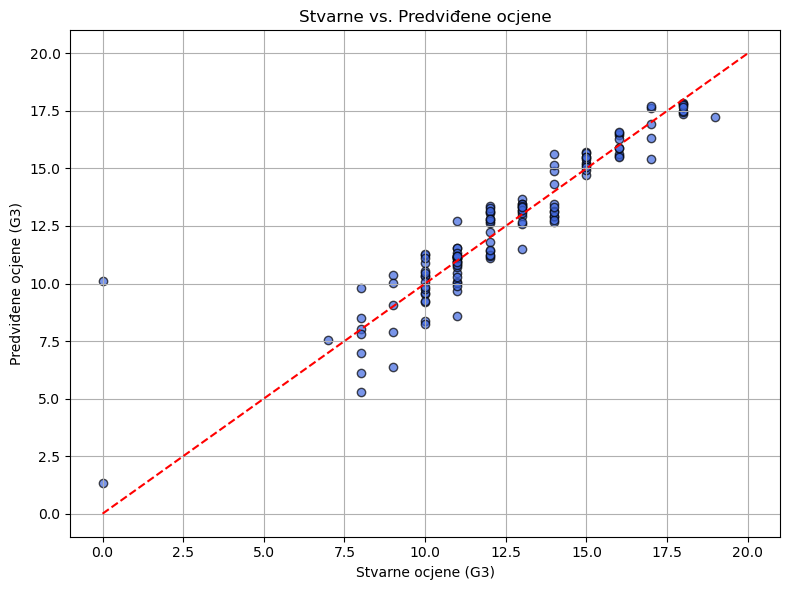

In [8]:
import matplotlib.pyplot as plt

# Scatter graf stvarnih vs. predviđenih ocjena
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='royalblue', edgecolors='k')
plt.plot([0, 20], [0, 20], color='red', linestyle='--')  # idealna linija
plt.xlabel('Stvarne ocjene (G3)')
plt.ylabel('Predviđene ocjene (G3)')
plt.title('Stvarne vs. Predviđene ocjene')
plt.grid(True)
plt.tight_layout()
plt.show()


In [9]:
import pickle

# Spremi sklearn model u .pkl datoteku
with open("model_strojno.pkl", "wb") as f:
    pickle.dump(model, f)
